In [58]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statistics import correlation
from scipy.stats import spearmanr
from scipy.stats import kruskal


In [4]:
job_df = pd.read_csv(r"C:\Users\ELITEX21012G2\Desktop\my projects\job salary prediction\job_salary_prediction_dataset.csv")
job_df


,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069
...,...,...,...,...,...,...,...,...,...,...
249995,Software Engineer,17,PhD,2,Telecom,Enterprise,India,No,1,127791
249996,Frontend Developer,20,PhD,7,Telecom,Startup,Remote,No,2,154593
249997,Business Analyst,1,Bachelor,12,Retail,Enterprise,India,Yes,0,75988
249998,Data Scientist,0,High School,2,Consulting,Small,Sweden,Hybrid,5,90467


Text(0.5, 1.0, 'Salary Distribution')

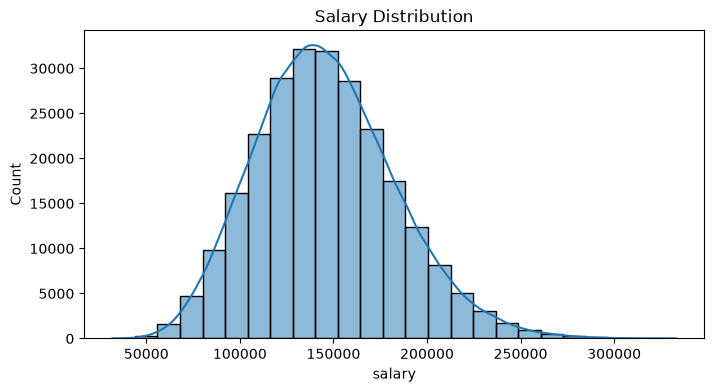

In [5]:
plt.figure(figsize=(8,4))
sns.histplot(data=job_df,x='salary',bins=25,kde=True)
plt.title("Salary Distribution")

In [6]:
s_mean = job_df['salary'].mean()
print("Mean: ",s_mean)
s_median = job_df['salary'].median()
print("Median: ",s_median)

Mean:  145718.080524
Median:  143453.0


__Distribution of the target variable (salary)__  
The salary distribution is concentrated around the middle range, with most employees earning between approximately KES 100,000 and KES 180,000. The distribution is slightly positively skewed, indicating that while most employees earn within the central salary range, a smaller number of employees receive substantially higher salaries. The long right tail suggests the presence of relatively high-paid employees, which may cause the mean salary to be higher than the median.


In [7]:
job_df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


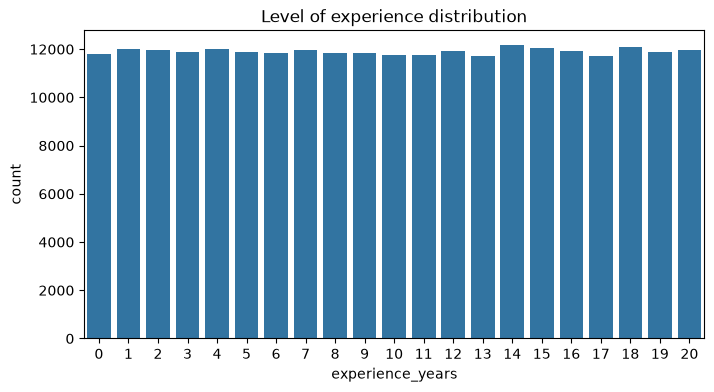

In [8]:
plt.figure(figsize=(8,4))
sns.countplot(data=job_df,x='experience_years')
plt.title('Level of experience distribution')
plt.show()

__Distribution of experience_years__  
The experience levels are spread uniformly across the workforce in the dataset and have no outliers.

In [9]:
job_df.head()


,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


Text(0.5, 1.0, 'Skills count distribution')

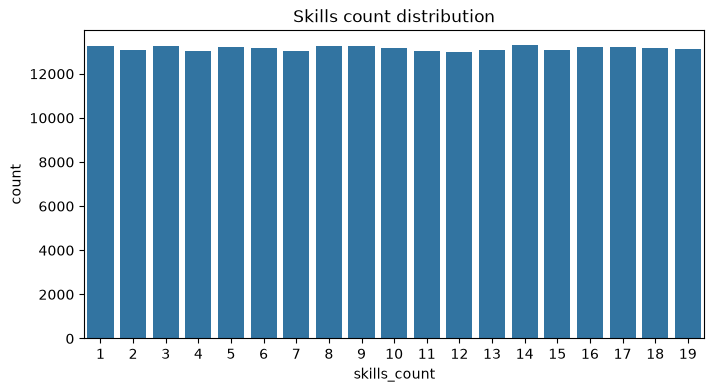

In [10]:
plt.figure(figsize=(8,4))
sns.countplot(data=job_df,x="skills_count")
plt.title("Skills count distribution")


The number of skills is fairly evenly distributed across employees. Employees are spread across a wide range of skills counts, from approximately 1 to 19, with no single value dominating the distribution, the overall pattern suggests that employees do not strongly cluster around a particular number of skills.

Text(0.5, 1.0, 'Certifications distribution')

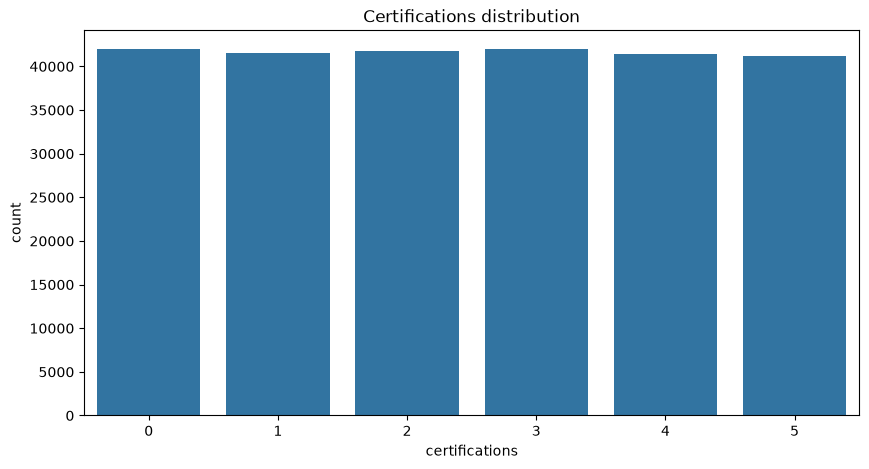

In [11]:
plt.figure(figsize=(10,5))
sns.countplot(data=job_df,x='certifications')
plt.title("Certifications distribution")


Certifications are fairly evenly distributed among employees. The number of employees with 0, 1, 2, 3, 4, or 5 certifications is relatively similar, indicating that employees do not cluster around a particular number of certifications.


__Conclusion__  
Combining both graphs:

Both skills_count and certifications are fairly evenly distributed rather than strongly clustered. Skills count is spread across approximately 1–19 skills, while certifications are almost uniformly distributed between 0 and 5 certifications. There is no particular value that dominates either distribution.

In [12]:
job_df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [13]:
columns_categorical = job_df.select_dtypes(include=['str','object']).columns.to_list()
columns_categorical 


['job_title',
 'education_level',
 'industry',
 'company_size',
 'location',
 'remote_work']

job_title
Backend Developer            21125
Cybersecurity Analyst        20959
Product Manager              20950
AI Engineer                  20945
Data Scientist               20890
DevOps Engineer              20889
Software Engineer            20876
Data Analyst                 20722
Cloud Engineer               20686
Machine Learning Engineer    20677
Business Analyst             20648
Frontend Developer           20633
Name: count, dtype: int64
********************************************************************************
education_level
Master         50352
High School    50065
Bachelor       49950
PhD            49857
Diploma        49776
Name: count, dtype: int64
********************************************************************************
industry
Finance          25393
Consulting       25258
Media            25034
Manufacturing    25024
Technology       24903
Government       24901
Healthcare       24898
Education        24889
Telecom          24859
Retail           24

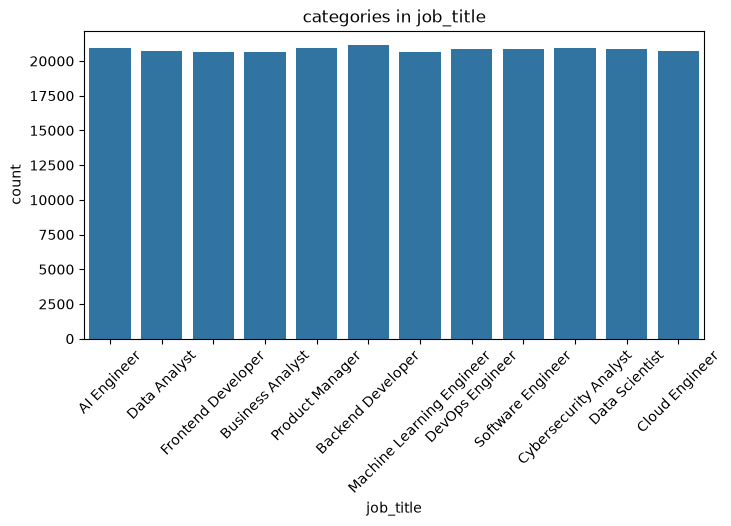

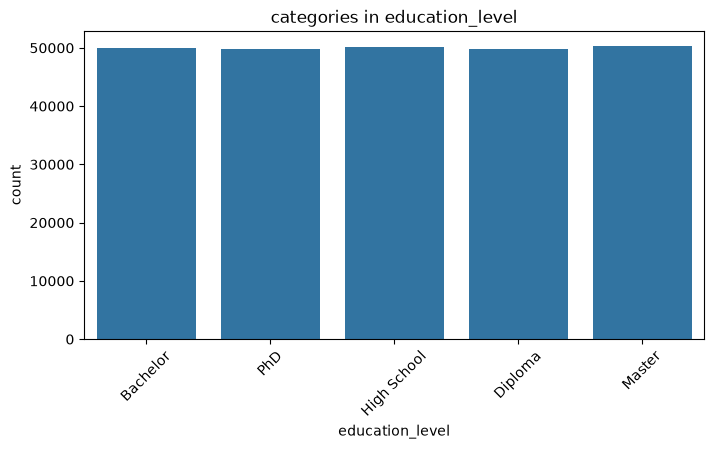

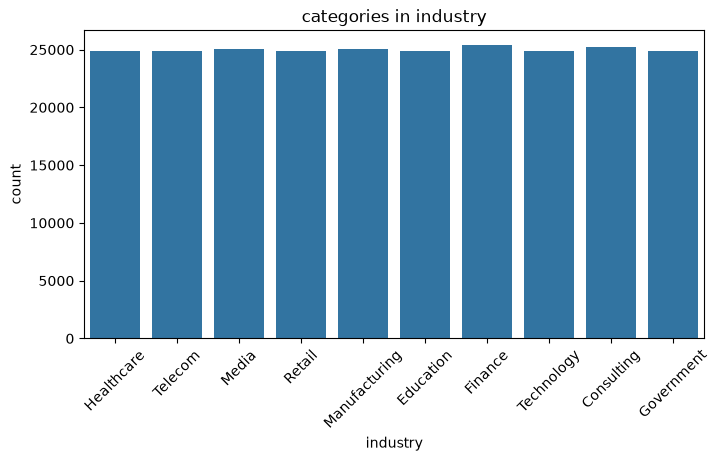

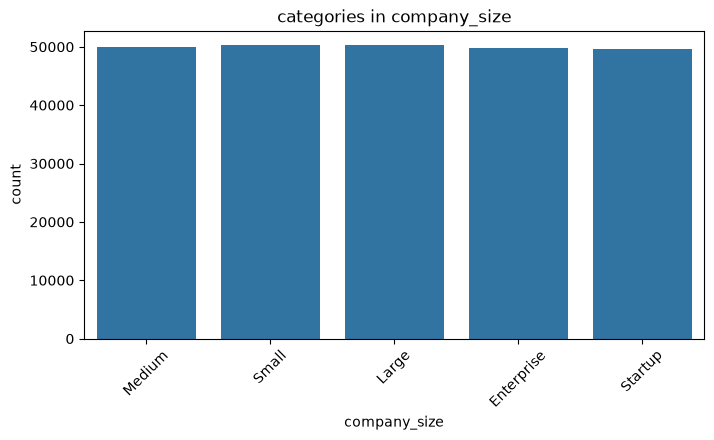

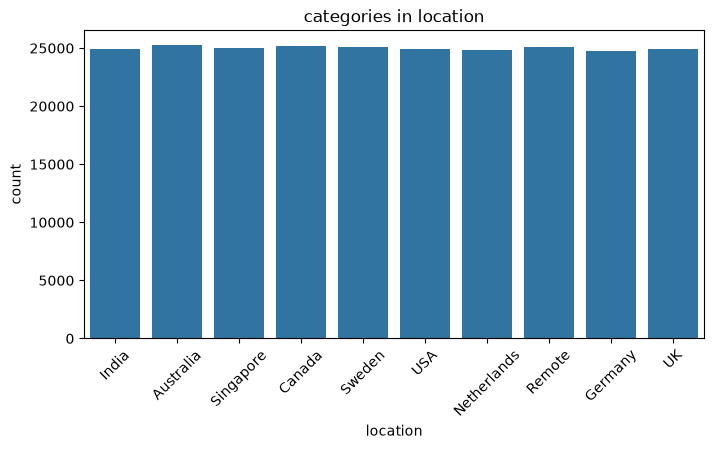

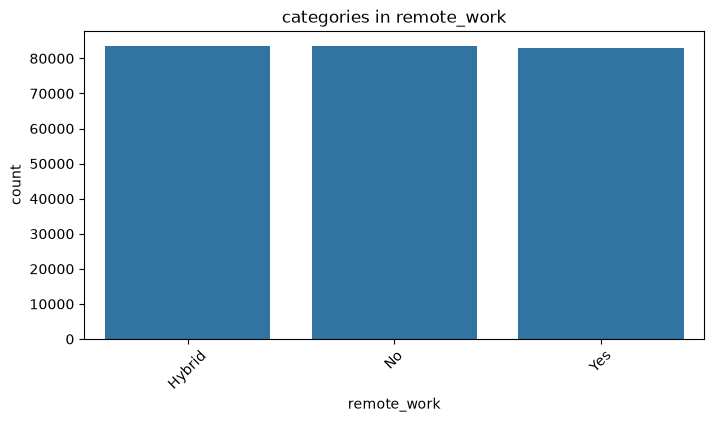

In [14]:
for column in columns_categorical:
    c_df =job_df[column].value_counts()
    print(c_df)
    print("*"*80)
    plt.figure(figsize=(8,4))
    sns.countplot(data=job_df,x=column)
    plt.xticks(rotation=45)
    plt.title(f"categories in {column}")

In [15]:
s = job_df['education_level'].value_counts(normalize=False,sort=True,dropna=False)
s

education_level
Master         50352
High School    50065
Bachelor       49950
PhD            49857
Diploma        49776
Name: count, dtype: int64

<Figure size 600x300 with 0 Axes>

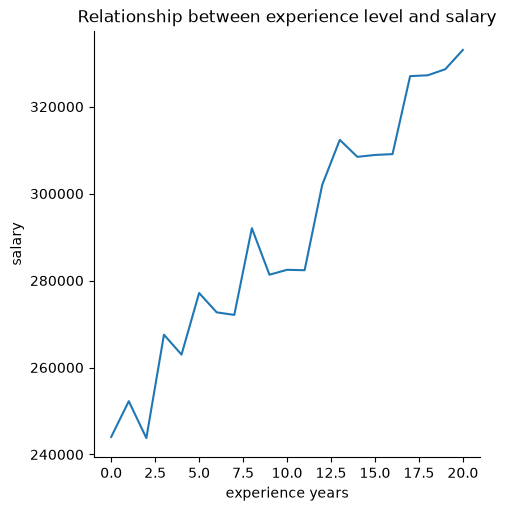

In [16]:
plt.figure(figsize=(6,3))
sns.relplot(data=job_df,x="experience_years",y="salary",kind="line",estimator="max",errorbar=None)
plt.title("Relationship between experience level and salary")
plt.xlabel('experience years')
plt.ylabel('salary')
plt.show()

__Relationship between salary and experience years__  
The analysis indicates a positive relationship between experience and salary. In general, employees with more years of experience tend to earn higher salaries. However, the relationship is not strictly linear, as salary fluctuates at several experience levels. The trend increases from approximately KES 240,000 for employees with no experience to over KES 330,000 for employees with 20 years of experience. This suggests that experience is an important factor associated with employee compensation.

<Figure size 600x300 with 0 Axes>

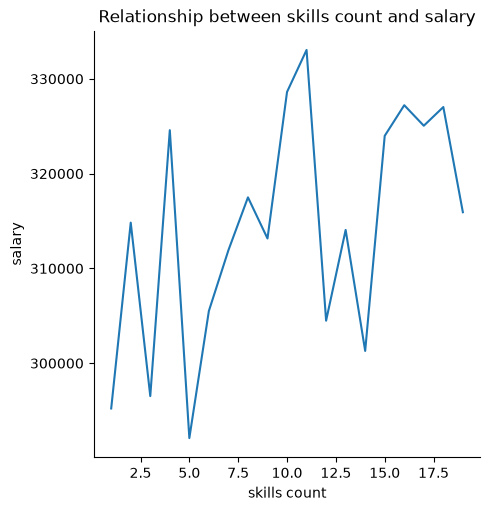

In [17]:
plt.figure(figsize=(6,3))
sns.relplot(data=job_df,x="skills_count",y="salary",kind="line",estimator="max",errorbar=None)
plt.title("Relationship between skills count and salary")
plt.xlabel('skills count')
plt.ylabel('salary')
plt.show()

__Relationship between skills count and salary__  
The analysis suggests a generally positive association between the number of skills an employee possesses and salary. Employees with higher skill counts tend to have relatively higher salaries, although the relationship shows considerable variation at different skill levels. The highest observed salary occurs around 11 skills, while salaries also remain relatively high among employees with 15–18 skills. This suggests that possessing a broader range of skills may be associated with higher compensation, but other factors may also contribute significantly to salary differences.

<Figure size 600x300 with 0 Axes>

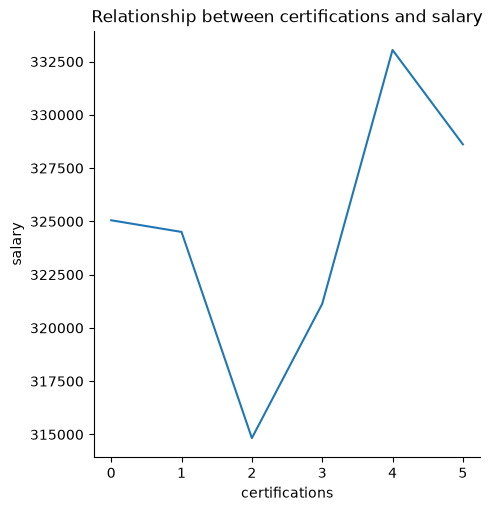

In [18]:
plt.figure(figsize=(6,3))
sns.relplot(data=job_df,x="certifications",y="salary",kind="line",estimator="max",errorbar=None)
plt.title("Relationship between certifications and salary")
plt.xlabel('certifications')
plt.ylabel('salary')
plt.show()

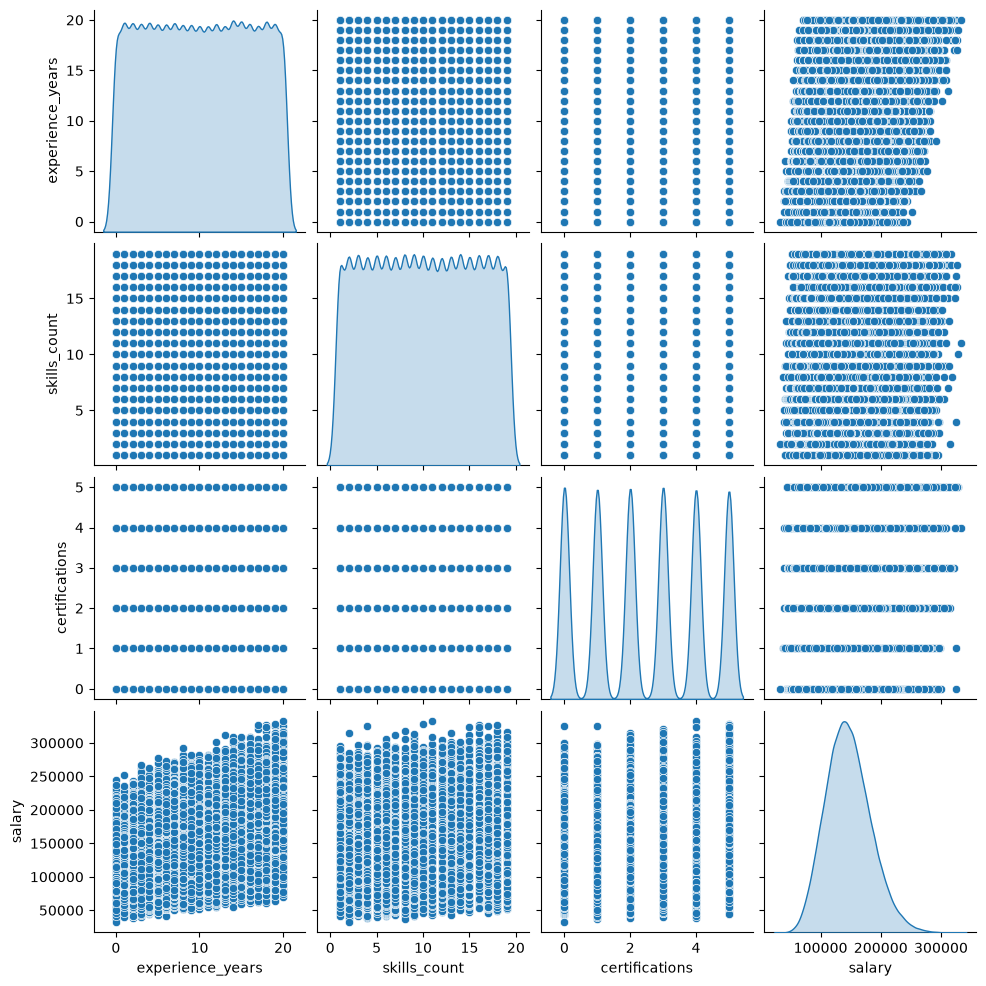

In [19]:
sns.pairplot(job_df,diag_kind='kde')
plt.show()

In [20]:
job_df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [21]:
ordinal_order = ['High School','Diploma','Bachelor','Master','PhD']
job_df['education_level'] = pd.Categorical(job_df['education_level'],
                                           categories=ordinal_order,
                                           ordered=True)

Text(0.5, 1.0, 'Relationshp between education level and salary')

<Figure size 600x300 with 0 Axes>

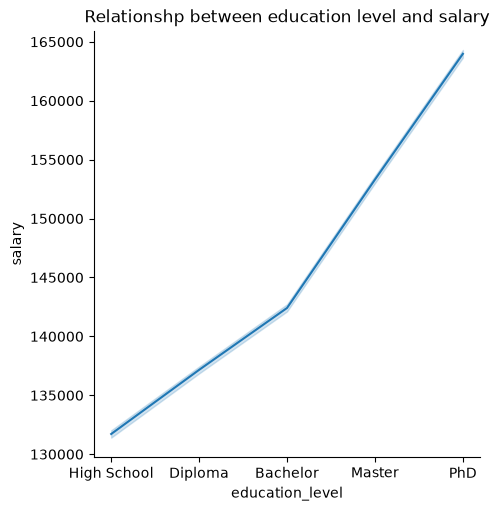

In [22]:
plt.figure(figsize=(6,3))
sns.relplot(data=job_df,x='education_level',y='salary',kind='line')
plt.title("Relationshp between education level and salary")

In [23]:
company_order = ['Small','Medium','Large']
job_df['company_size'] = pd.Categorical(job_df['company_size'],
                                        categories=company_order,
                                        ordered=True)

C:\Users\ELITEX21012G2\AppData\Local\Temp\ipykernel_7576\1338888926.py:2: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  job_df['company_size'] = pd.Categorical(job_df['company_size'],


Text(0.5, 1.0, 'Relationship between company size and salary')

<Figure size 600x300 with 0 Axes>

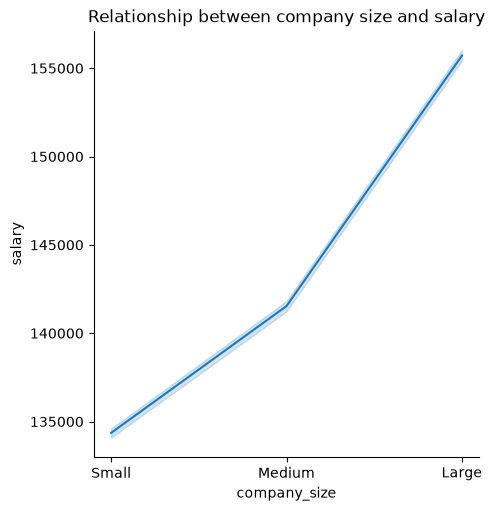

In [24]:
plt.figure(figsize=(6,3))
sns.relplot(data=job_df,x='company_size',y='salary',kind='line')
plt.title("Relationship between company size and salary")

Text(0.5, 1.0, 'Relationship between remote work and salary')

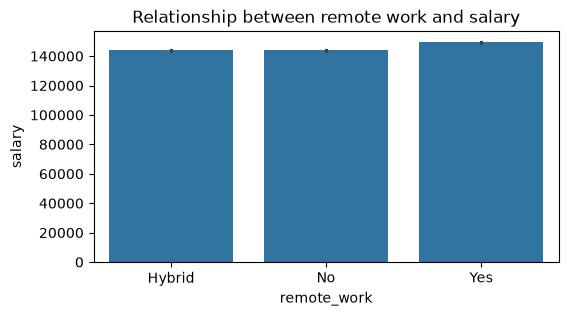

In [25]:
plt.figure(figsize=(6,3))
sns.barplot(data=job_df,x='remote_work',y='salary')
plt.title("Relationship between remote work and salary")


Text(0.5, 1.0, 'salary distribution across job titles')

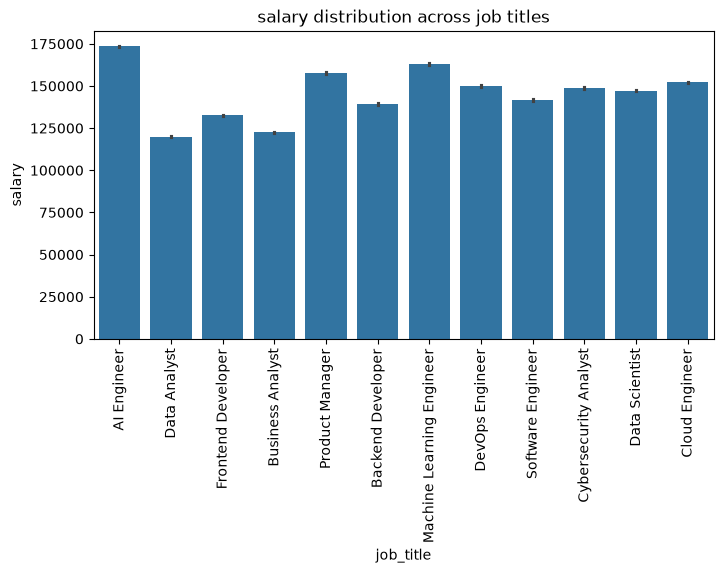

In [26]:
plt.figure(figsize=(8,4))
sns.barplot(data=job_df,x='job_title',y='salary')
plt.xticks(rotation=90)
plt.title("salary distribution across job titles")

<Axes: xlabel='salary', ylabel='job_title'>

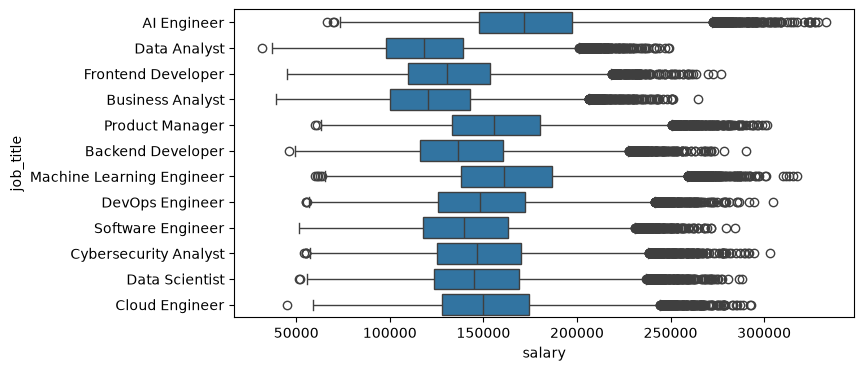

In [27]:
plt.figure(figsize=(8,4))
sns.boxplot(data=job_df,x='salary',y='job_title')

In [28]:
job_df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


<Axes: xlabel='salary', ylabel='industry'>

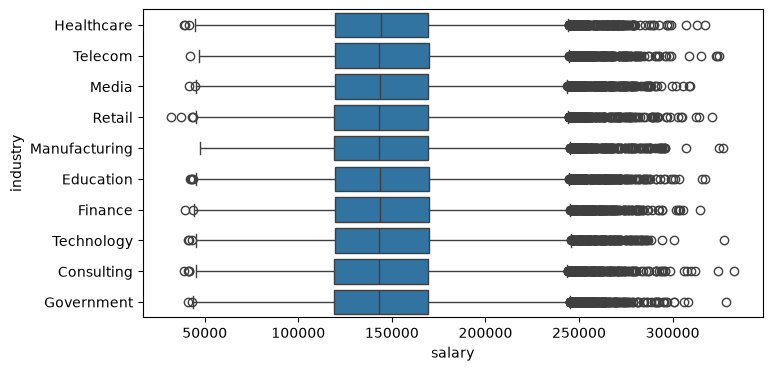

In [29]:
plt.figure(figsize=(8,4))
sns.boxplot(data=job_df,x='salary',y='industry')

<Axes: xlabel='salary', ylabel='location'>

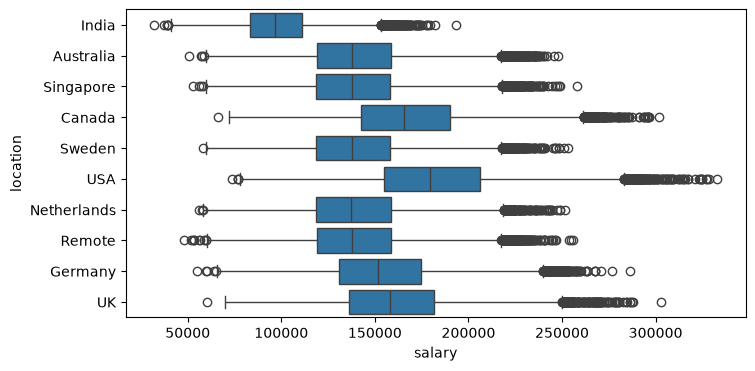

In [30]:
plt.figure(figsize=(8,4))
sns.boxplot(data=job_df,x='salary',y='location')

<Axes: xlabel='education_level', ylabel='salary'>

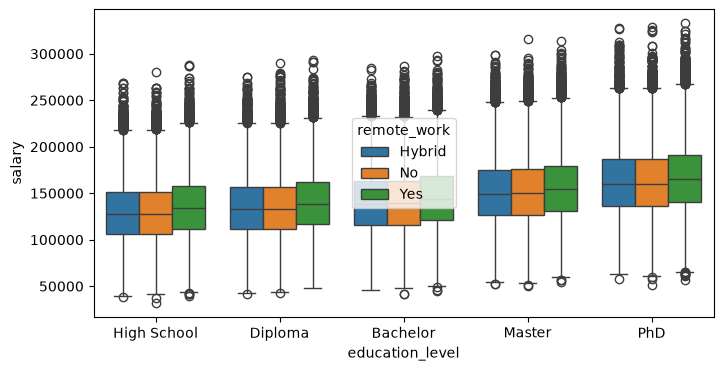

In [31]:
plt.figure(figsize=(8,4))
sns.boxplot(data=job_df,x='education_level',y='salary',hue='remote_work')


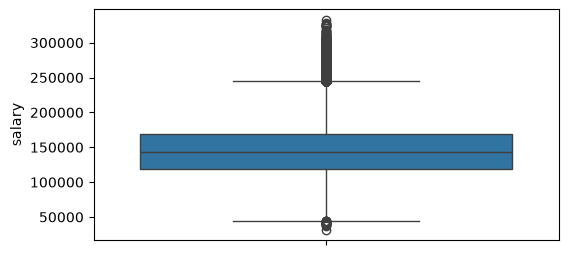

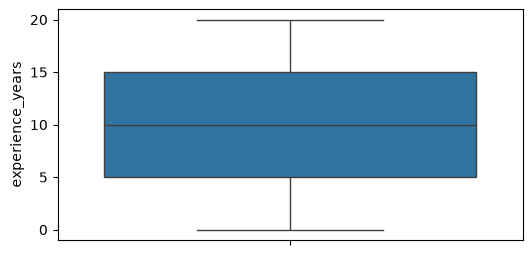

In [32]:
b_cols = ['salary', 'experience_years']
for column in b_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(data=job_df,y=column)

In [33]:
job_df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [34]:
def find_outliers(column):
    Q1 = job_df[column].quantile(0.25)
    Q3 = job_df[column].quantile(0.75)
    IQR =Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = job_df[(job_df[column] < lower_bound) | (job_df[column] > upper_bound)]

    return outliers,lower_bound,upper_bound

salary_outliers, salary_lower, salary_upper = find_outliers('salary')
experience_outliers, exp_lower, exp_upper = find_outliers('experience_years')

print("Salary outliers:", len(salary_outliers))
print("Salary lower bound:", salary_lower)
print("Salary upper bound:", salary_upper)

print("\nYears of experience outliers:", len(experience_outliers))
print("Experience lower bound:", exp_lower)
print("Experience upper bound:", exp_upper)

Salary outliers: 2336
Salary lower bound: 44157.0
Salary upper bound: 244693.0

Years of experience outliers: 0
Experience lower bound: -10.0
Experience upper bound: 30.0


In [35]:
numerical_cols = job_df.select_dtypes(include=['int','float']).columns.to_list()
#numerical_cols.remove("salary")
numerical_cols

['experience_years', 'skills_count', 'certifications', 'salary']

<Axes: >

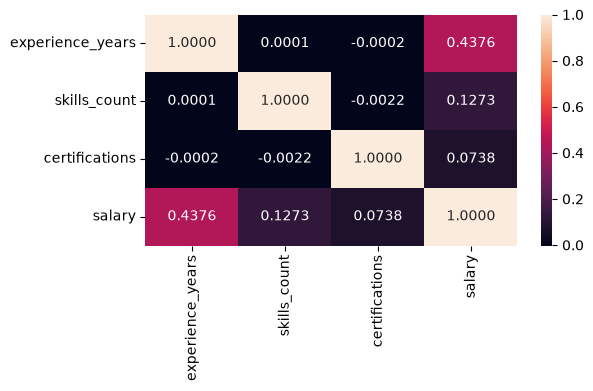

In [36]:
num_corr = job_df[numerical_cols].corr()
plt.figure(figsize=(6,3))
sns.heatmap(num_corr,annot=True,fmt='.4f')

The scatterplot shows a generally positive monotonic relationship between experience years and salary. As experience increases, the salary distribution tends to shift upward, although there is considerable variation in salary at each experience level. The salary distribution is slightly right-skewed and contains several potential outliers. Because of these characteristics, Spearman's rank correlation was selected as it is a non-parametric measure that is less sensitive to extreme values and does not require normally distributed variables.

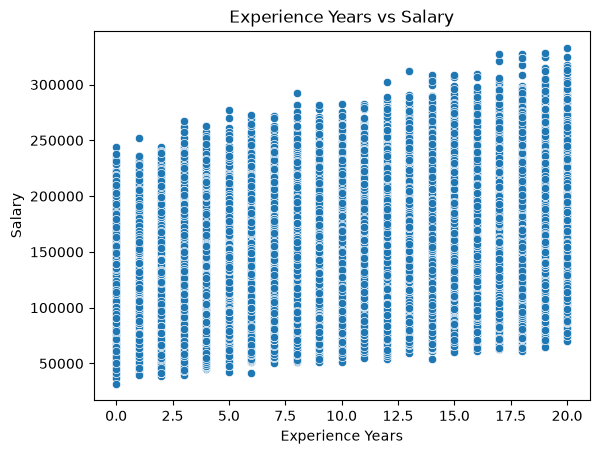

In [ ]:

sns.scatterplot(
    data=job_df,
    x='experience_years',
    y='salary'
)

plt.title('Experience Years vs Salary')
plt.xlabel('Experience Years')
plt.ylabel('Salary')
plt.show()

In [43]:

H0 = "There is no statistical significant relationship between experience years and salary"
H1 = "There is a statistical significant relationship between experience years and salary"
rho,p_value = spearmanr(job_df['salary'],job_df['experience_years'])

alpha = 0.05
if p_value < alpha:
    print(f"p value: {p_value}")
    print(f"Test Statistic: {rho}")
    print(f"We reject the null hypothesis '{H0}'")
else:
    print(f"p value: {p_value}")
    print(f"Test Statistic: {rho}")
    print(f"We fail to reject the null hypothesis '{H0}' and conclude {H1}")

p value: 0.0
Test Statistic: 0.4378908365374024
We reject the null hypothesis 'There is no statistical significant relationship between experience years and salary'


<Axes: xlabel='skills_count', ylabel='Count'>

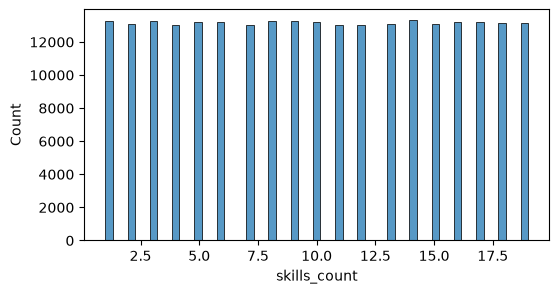

In [45]:
plt.figure(figsize=(6,3))
sns.histplot(data=job_df,x='skills_count')

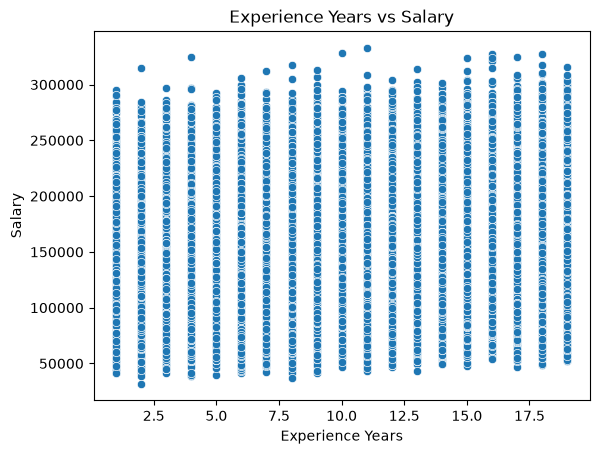

In [46]:

sns.scatterplot(
    data=job_df,
    x='skills_count',
    y='salary'
)

plt.title('Experience Years vs Salary')
plt.xlabel('Experience Years')
plt.ylabel('Salary')
plt.show()

In [44]:

H0 = "There is no statistical significant relationship between skills count and salary"
H1 = "There is a statistical significant relationship between skills count and salary"
rho,p_value = spearmanr(job_df['salary'],job_df['skills_count'])

alpha = 0.05
if p_value < alpha:
    print(f"p value: {p_value}")
    print(f"Test Statistic: {rho}")
    print(f"We reject the null hypothesis '{H0}'")
else:
    print(f"p value: {p_value}")
    print(f"Test Statistic: {rho}")
    print(f"We fail to reject the null hypothesis '{H0}' and conclude {H1}")

p value: 0.0
Test Statistic: 0.1251795691962756
We reject the null hypothesis 'There is no statistical significant relationship between skills count and salary'


In [47]:

H0 = "There is no statistical significant relationship between certifications and salary"
H1 = "There is a statistical significant relationship between certifications and salary"
rho,p_value = spearmanr(job_df['salary'],job_df['certifications'])

alpha = 0.05
if p_value < alpha:
    print(f"p value: {p_value}")
    print(f"Test Statistic: {rho}")
    print(f"We reject the null hypothesis '{H0}'")
else:
    print(f"p value: {p_value}")
    print(f"Test Statistic: {rho}")
    print(f"We fail to reject the null hypothesis '{H0}' and conclude {H1}")

p value: 3.3234543362036397e-284
Test Statistic: 0.07195817320337657
We reject the null hypothesis 'There is no statistical significant relationship between certifications and salary'


In [56]:
job_df.groupby('education_level')['salary'].describe()

,count,mean,std,min,25%,50%,75%,max
education_level,,,,,,,,
High School,50065.0,131715.336243,33601.793888,31867.0,107881.00,129663.0,153269.00,287961.0
Diploma,49776.0,137158.574976,34275.205234,41812.0,113138.75,135283.0,158873.00,293306.0
Bachelor,49950.0,142410.531291,35105.903931,41276.0,117857.75,140631.5,164885.75,298070.0
Master,50352.0,153305.307833,36529.815853,50201.0,127729.75,151396.5,176683.75,315928.0
PhD,49857.0,163976.005295,38149.434745,50823.0,137637.00,162005.0,188370.00,333046.0


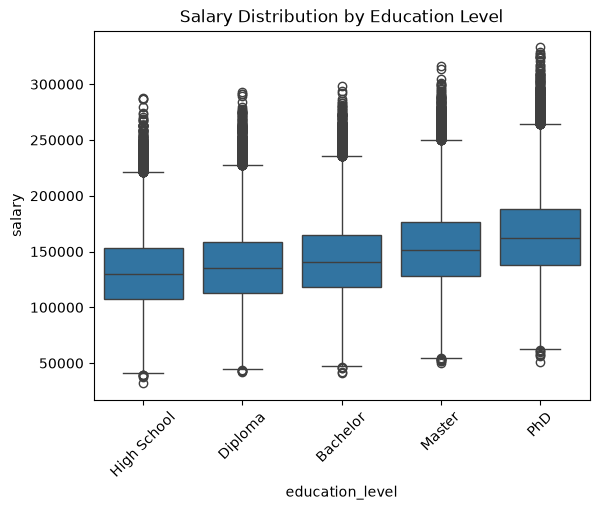

In [57]:
sns.boxplot(
    data=job_df,
    x='education_level',
    y='salary'
)

plt.title('Salary Distribution by Education Level')
plt.xticks(rotation=45)
plt.show()

In [61]:
H_0 = "The salary distributions are the same across the education-level groups."

H_1 = "At least one education-level group has a different salary distribution."

groups = [group["salary"].values for name,group in job_df.groupby("education_level")]
stat , p_value = kruskal(*groups)

alpha = 0.05

print(f"H statistic: {stat}")
print(f"p value: {p_value}")

if p_value < alpha:
    print(f"Reject null hypotheses '{H_0}'")
else:
    print(f"Fail to reject the null hypothesis '{H_0}'")

H statistic: 23098.37298106752
p value: 0.0
Reject null hypotheses 'The salary distributions are the same across the education-level groups.'


In [63]:
job_df.groupby('company_size')['salary'].describe()

,count,mean,std,min,25%,50%,75%,max
company_size,,,,,,,,
Small,50235.0,134356.864298,31247.189000,39285.0,112662.0,134001.0,155027.50,270596.0
Medium,50027.0,141537.535991,32942.663686,41108.0,118503.5,140861.0,163342.00,274496.0
Large,50254.0,155711.112489,36364.880007,45599.0,130438.0,154981.0,179675.75,306036.0


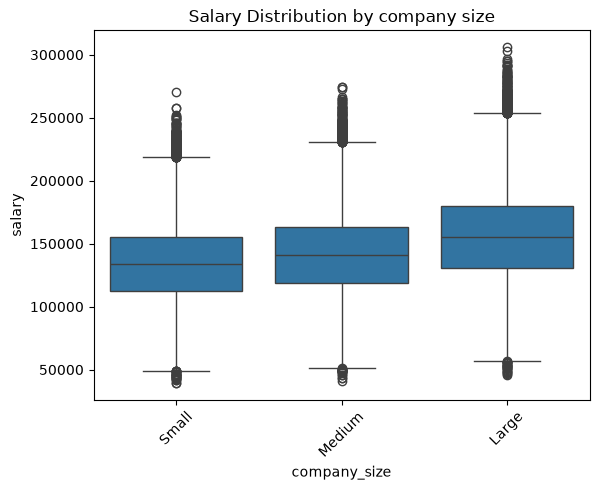

In [64]:
sns.boxplot(
    data=job_df,
    x='company_size',
    y='salary'
)

plt.title('Salary Distribution by company size')
plt.xticks(rotation=45)
plt.show()

In [65]:
H_0 = "The salary distributions are the same across the company sizes."

H_1 = "At least one company size has a different salary distribution."

groups = [group["salary"].values for name,group in job_df.groupby("company_size")]
stat , p_value = kruskal(*groups)

alpha = 0.05

print(f"H statistic: {stat}")
print(f"p value: {p_value}")

if p_value < alpha:
    print(f"Reject null hypotheses '{H_0}'")
else:
    print(f"Fail to reject the null hypothesis '{H_0}'")

H statistic: 9099.365351863287
p value: 0.0
Reject null hypotheses 'The salary distributions are the same across the company sizes.'


<Axes: xlabel='education_level', ylabel='Count'>

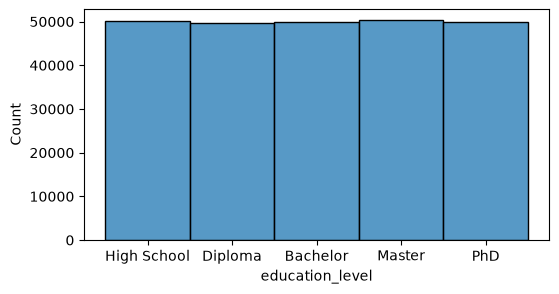

In [51]:
h = job_df["education_level"].unique()
h
#for cat in h:
plt.figure(figsize=(6,3))
sns.histplot(data=job_df,x='education_level')

In [38]:
job_df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069
